## Importing the libraries

In [ ]:
# Install required external packages
%pip install xgboost

In [9]:
# Import foundational numerical and data manipulation libraries
import numpy as np
import pandas as pd

In [11]:
# Import data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
# Configure warning settings and plot inline display
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
sns.set_style("whitegrid")

In [13]:
# Import preprocessing, model selection, and evaluation metrics
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score

In [14]:
# Import machine learning classification models
from sklearn.linear_model import LogisticRegression as Logreg
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import xgboost as xgb

## Load and Prepare Data

In [15]:
# Load the dataset files into pandas dataframes
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
sample_sub = pd.read_csv("sampleSubmission.csv")

In [16]:
# Display dataset shapes and dimensions
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Sample submission shape:", sample_sub.shape)

Train shape: (891, 12)
Test shape: (418, 11)
Sample submission shape: (418, 2)


In [17]:
# Preview the first five rows of the training dataset
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [18]:
# Preview the last five rows of the training dataset
train_df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [19]:
# Display summary information including column types and non-null counts
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [20]:
# Display descriptive statistics for all columns
train_df.describe(include='all')

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


## EDA

In [21]:
# Identify missing values count per column in training data
train_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [22]:
# Identify missing values count per column in test data
test_df.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

In [23]:
# Calculate and display the distribution of the target variable (Survived)
train_df['Survived'].value_counts(normalize=True)

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

In [24]:
# Calculate survival rates grouped by passenger gender
train_df.groupby('Sex')['Survived'].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [25]:
# Calculate survival rates grouped by passenger class
train_df.groupby('Pclass')['Survived'].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [26]:
# Calculate survival rates grouped by port of embarkation
train_df.groupby('Embarked')['Survived'].mean()

Embarked
C    0.553571
Q    0.389610
S    0.336957
Name: Survived, dtype: float64

In [27]:
# Compute correlation matrix for numeric columns
corr = train_df.select_dtypes(include=[np.number]).corr()
corr

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
PassengerId,1.000000,-0.005007,-0.035144,0.036847,-0.057527,-0.001652,0.012658
Survived,-0.005007,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
Pclass,-0.035144,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
Age,0.036847,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
SibSp,-0.057527,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
Parch,-0.001652,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
Fare,0.012658,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


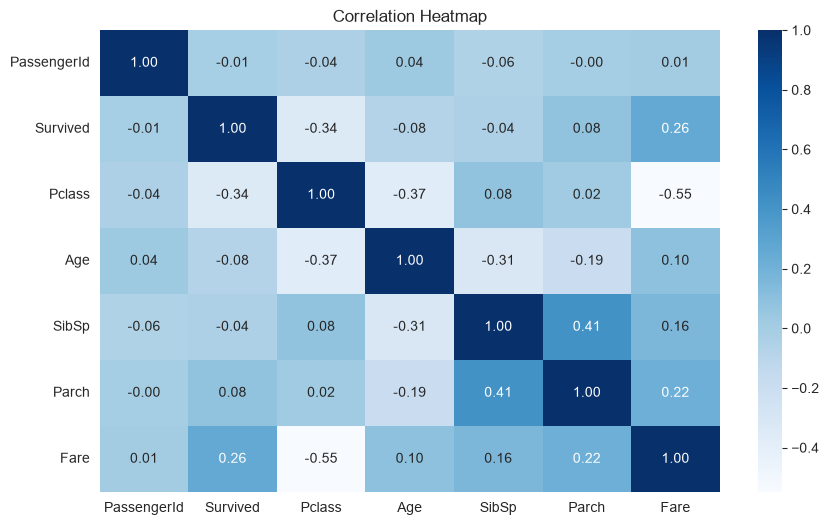

In [28]:
# Plot correlation heatmap using seaborn
plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, cmap="Blues", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

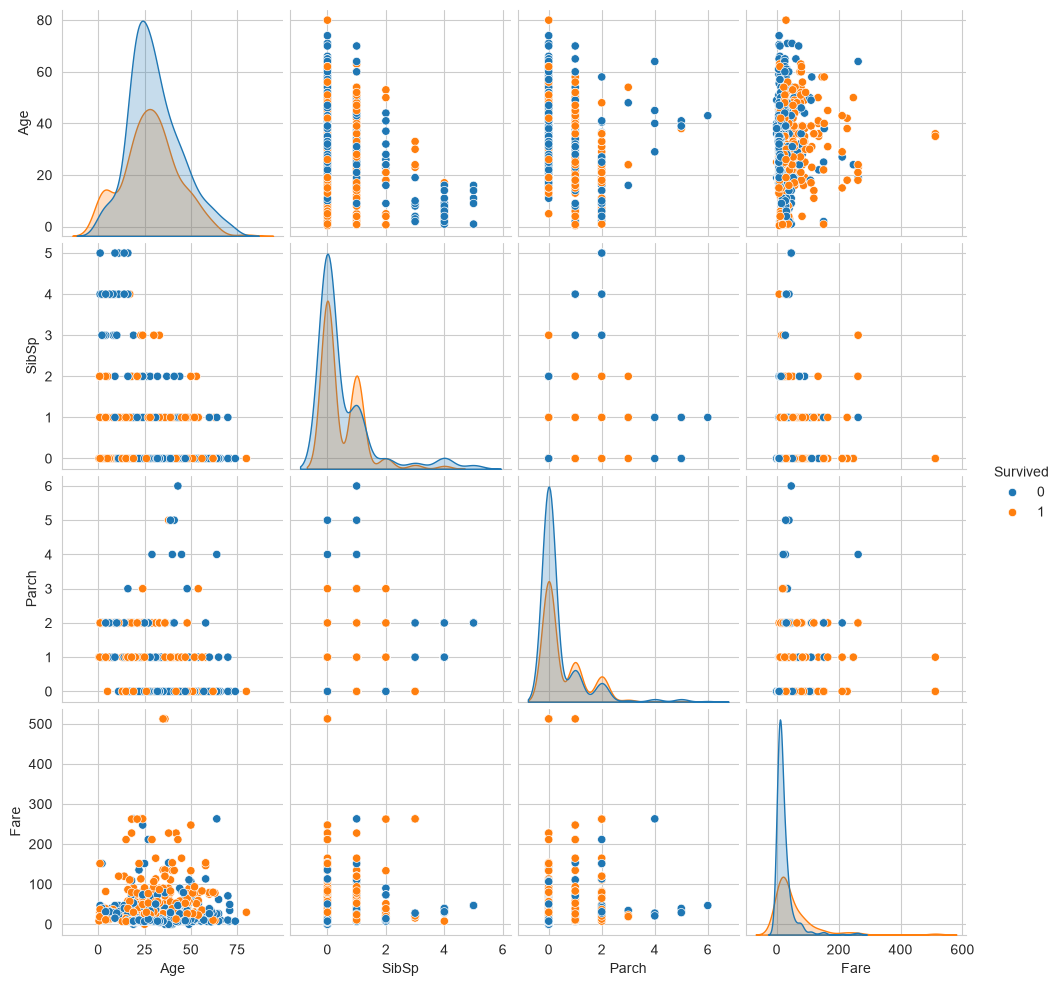

In [29]:
# Generate pairplot across key numeric features segmented by survival
sns.pairplot(train_df[['Survived', 'Age', 'SibSp', 'Parch', 'Fare']].dropna(), hue='Survived')
plt.show()

## Data Preprocessing

In [30]:
# Create working copies of train and test datasets
train = train_df.copy()
test = test_df.copy()

In [31]:
# Extract passenger title from the Name column
train['Title'] = train['Name'].str.extract(r',\s*([^\.]+)\.', expand=False)
test['Title'] = test['Name'].str.extract(r',\s*([^\.]+)\.', expand=False)

In [32]:
# Group rare titles into a unified category
rare_titles = ['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona']
train['Title'] = train['Title'].replace(rare_titles, 'Rare')
test['Title'] = test['Title'].replace(rare_titles, 'Rare')
train['Title'] = train['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
test['Title'] = test['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})

In [33]:
# Fill missing Embarked values with the most frequent value (mode)
train['Embarked'] = train['Embarked'].fillna(train['Embarked'].mode()[0])

In [34]:
# Fill missing Fare value in the test set with the median
test['Fare'] = test['Fare'].fillna(train['Fare'].median())

In [35]:
# Impute missing Age values based on Sex and Pclass group medians
train['Age'] = train.groupby(['Sex', 'Pclass'])['Age'].transform(lambda x: x.fillna(x.median()))
test['Age'] = test.groupby(['Sex', 'Pclass'])['Age'].transform(lambda x: x.fillna(x.median()))

In [36]:
# Create binary indicator indicating whether Cabin information is present
train['HasCabin'] = train['Cabin'].notnull().astype(int)
test['HasCabin'] = test['Cabin'].notnull().astype(int)

In [37]:
# Drop raw columns that have been processed or are non-predictive
drop_cols = ['Name', 'Ticket', 'Cabin']
train = train.drop(columns=drop_cols)
test = test.drop(columns=drop_cols)

In [38]:
# Separate features and target label from the training dataset
X = train.drop(columns=['PassengerId', 'Survived'])
y = train['Survived']
X_test_final = test.drop(columns=['PassengerId'])

In [39]:
# Apply one-hot encoding on categorical variables using get_dummies
X_encoded = pd.get_dummies(X, columns=['Sex', 'Embarked', 'Title'], drop_first=True)
T_encoded = pd.get_dummies(X_test_final, columns=['Sex', 'Embarked', 'Title'], drop_first=True)

In [40]:
# Align train and test feature columns to maintain identical schema
X_encoded, T_encoded = X_encoded.align(T_encoded, join='left', axis=1, fill_value=0)

In [41]:
# Split the training data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X_encoded, y, test_size=0.2, random_state=42, stratify=y)

In [42]:
# Standardize features using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_full_scaled = scaler.fit_transform(X_encoded)
T_full_scaled = scaler.transform(T_encoded)

## Strorytelling - Visualization

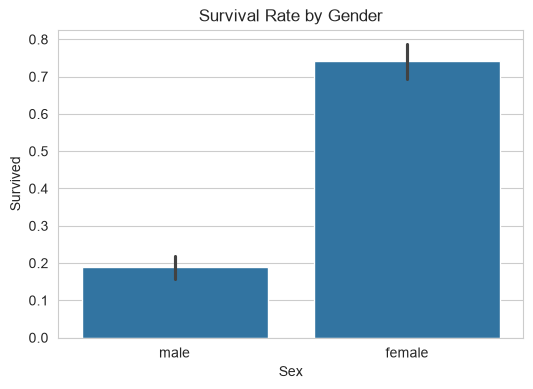

In [43]:
# Bar plot for survival rate by gender
plt.figure(figsize=(6, 4))
sns.barplot(data=train_df, x='Sex', y='Survived')
plt.title("Survival Rate by Gender")
plt.show()

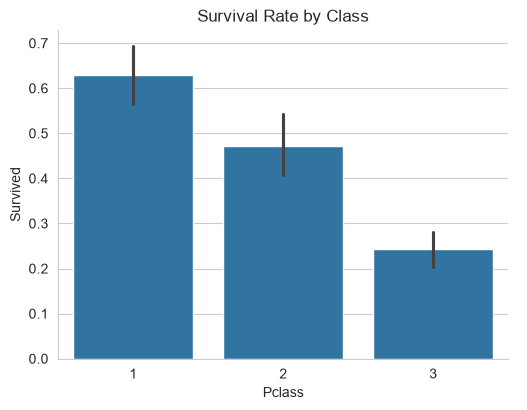

In [44]:
# Categorical plot for survival rate by passenger class
sns.catplot(data=train_df, x='Pclass', y='Survived', kind='bar', height=4, aspect=1.3)
plt.title("Survival Rate by Class")
plt.show()

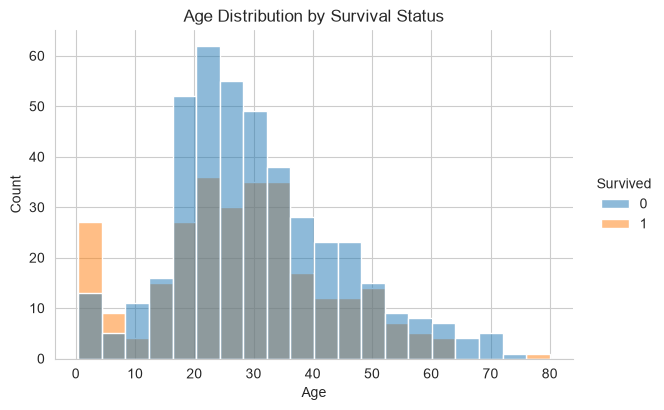

In [45]:
# Distribution plot for passenger age conditioned on survival
sns.displot(data=train_df, x='Age', hue='Survived', fill=True, height=4, aspect=1.5)
plt.title("Age Distribution by Survival Status")
plt.show()

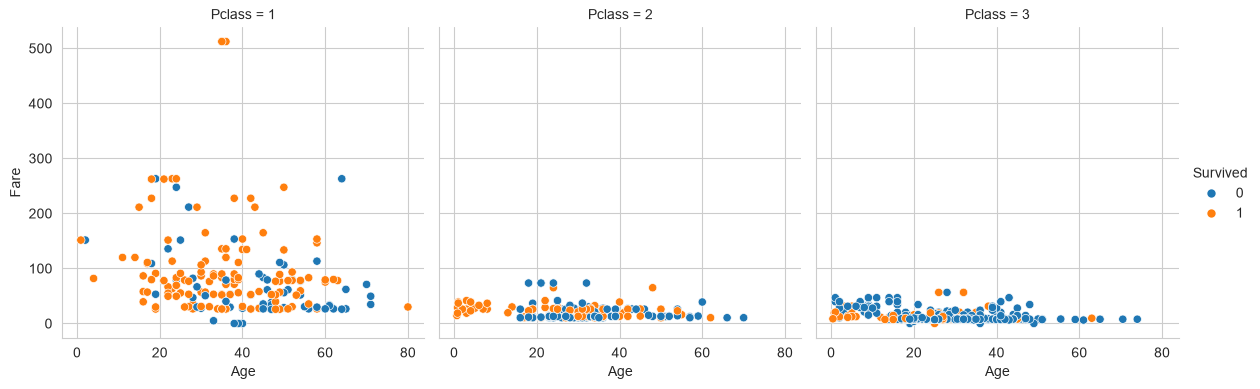

In [46]:
# Relational plot of Age versus Fare segmented by Class and Survival
sns.relplot(data=train_df, x='Age', y='Fare', hue='Survived', col='Pclass', height=4, aspect=1)
plt.show()

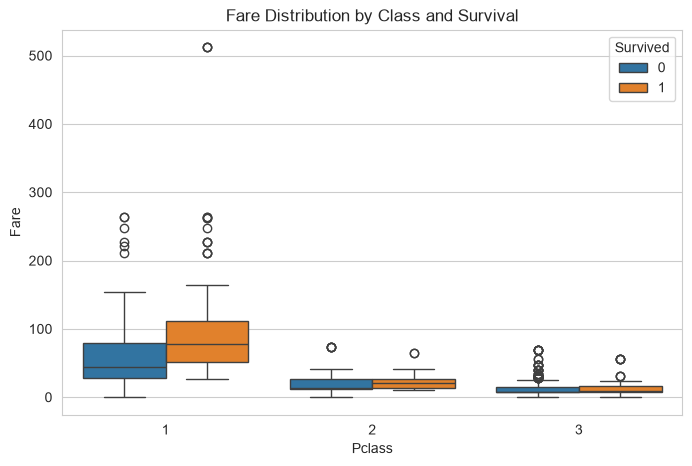

In [47]:
# Box plot showing Fare distributions across classes and survival status
plt.figure(figsize=(8, 5))
sns.boxplot(data=train_df, x='Pclass', y='Fare', hue='Survived')
plt.title("Fare Distribution by Class and Survival")
plt.show()

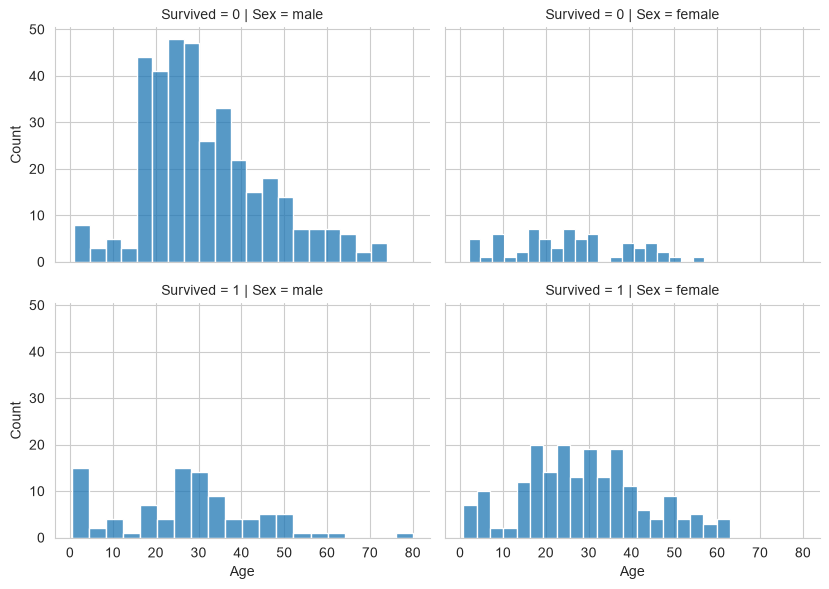

In [48]:
# FacetGrid displaying age histograms by Gender and Survival status
g = sns.FacetGrid(train_df, col="Sex", row="Survived", height=3, aspect=1.4)
g.map(sns.histplot, "Age", bins=20)
plt.show()

## Train your model (Classification)

In [49]:
# Initialize and evaluate Logistic Regression
log_model = Logreg(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)
y_pred_log = log_model.predict(X_val_scaled)
print("Logistic Regression Accuracy:", accuracy_score(y_val, y_pred_log))
print("Confusion Matrix:\n", confusion_matrix(y_val, y_pred_log))

Logistic Regression Accuracy: 0.8379888268156425
Confusion Matrix:
 [[97 13]
 [16 53]]


In [50]:
# Initialize and evaluate K-Nearest Neighbors Classifier
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_val_scaled)
print("KNN Accuracy:", accuracy_score(y_val, y_pred_knn))
print("Confusion Matrix:\n", confusion_matrix(y_val, y_pred_knn))

KNN Accuracy: 0.8212290502793296
Confusion Matrix:
 [[96 14]
 [18 51]]


In [51]:
# Initialize and evaluate Decision Tree Classifier
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_val)
print("Decision Tree Accuracy:", accuracy_score(y_val, y_pred_dt))
print("Confusion Matrix:\n", confusion_matrix(y_val, y_pred_dt))

Decision Tree Accuracy: 0.8100558659217877
Confusion Matrix:
 [[96 14]
 [20 49]]


In [52]:
# Initialize and evaluate Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_val)
print("Random Forest Accuracy:", accuracy_score(y_val, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_val, y_pred_rf))

Random Forest Accuracy: 0.8044692737430168
Confusion Matrix:
 [[99 11]
 [24 45]]


In [53]:
# Initialize and evaluate Support Vector Classifier (SVC)
svm_model = SVC(kernel='rbf', C=1.0, random_state=42)
svm_model.fit(X_train_scaled, y_train)
y_pred_svm = svm_model.predict(X_val_scaled)
print("SVM Accuracy:", accuracy_score(y_val, y_pred_svm))
print("Confusion Matrix:\n", confusion_matrix(y_val, y_pred_svm))

SVM Accuracy: 0.8268156424581006
Confusion Matrix:
 [[99 11]
 [20 49]]


In [54]:
# Initialize and evaluate XGBoost Classifier
xgb_model = xgb.XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.05, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_val)
print("XGBoost Accuracy:", accuracy_score(y_val, y_pred_xgb))
print("Confusion Matrix:\n", confusion_matrix(y_val, y_pred_xgb))

XGBoost Accuracy: 0.8044692737430168
Confusion Matrix:
 [[97 13]
 [22 47]]


In [55]:
# Perform 5-fold cross validation for the Random Forest model
cv_scores = cross_val_score(rf_model, X_encoded, y, cv=5, scoring='accuracy')
print("Cross-Validation Scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())

Cross-Validation Scores: [0.83240223 0.80337079 0.82022472 0.79213483 0.86516854]
Mean CV Accuracy: 0.8226602222082731


In [56]:
# Hyperparameter tuning for Random Forest using GridSearchCV
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [4, 6, 8]
}
grid_search = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_encoded, y)
print("Best Parameters:", grid_search.best_params_)
print("Best CV Score:", grid_search.best_score_)

Best Parameters: {'max_depth': 6, 'n_estimators': 200}
Best CV Score: 0.8226602222082731


## Test Result

In [57]:
# Fit the best optimized model on the full training dataset
best_model = grid_search.best_estimator_
best_model.fit(X_encoded, y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [58]:
# Generate predictions on the test dataset
test_predictions = best_model.predict(T_encoded)
test_predictions[:10]

array([0, 0, 0, 0, 1, 0, 1, 0, 1, 0])

In [59]:
# Create submission dataframe matching sampleSubmission structure
submission = pd.DataFrame({
    'PassengerId': test_df['PassengerId'],
    'Survived': test_predictions
})
submission.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


In [60]:
# Export submission dataframe to CSV file
submission.to_csv("submission.csv", index=False)
print("Submission saved successfully as submission.csv")

Submission saved successfully as submission.csv
